# Apartment Hunter — Modélisation du prix (King County)

**Problématique :** peut-on estimer le prix de vente d'un bien immobilier à partir de ses caractéristiques, avec une précision suffisante pour servir d'outil d'aide à l'estimation pour un agent immobilier ?

Ce notebook couvre les étapes **9 et 10** du projet (l'étape 8, la sélection de variables, est dans `01_selection_features.ipynb`) :

1. Chargement des données et reprise de la préparation du notebook 01
2. Découpage **train / test groupé par `id`** (une maison vendue deux fois ne doit pas être à la fois dans le train et dans le test)
3. **Comparaison de 5 algorithmes** de régression (validation croisée groupée)
4. **Grid search** pour optimiser les meilleurs modèles
5. Évaluation finale sur le jeu de test, analyse des erreurs, importance des variables
6. Sauvegarde du modèle pour l'application Flask

## 0. Imports et paramètres

In [7]:
%pip install matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [8]:
import warnings; warnings.filterwarnings("ignore")
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

sns.set_theme(style="whitegrid"); RS = 42

# Les chemins fonctionnent que le notebook soit lancé depuis notebooks/ ou depuis la racine du repo
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_PATH  = ROOT / "data" / "kc_house_data.csv"
MODEL_DIR  = ROOT / "model"; MODEL_DIR.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| données :", DATA_PATH.resolve())

scikit-learn 1.8.0 | données : C:\Users\pierr\Desktop\apartment-hunter\apartment-hunter\data\kc_house_data.csv


## 1. Chargement et préparation

On reprend **exactement** la préparation du notebook 01, pour que les variables soient identiques :
- nettoyage des guillemets parasites du CSV (`id`, `date`, `floors`, `zipcode` sont lus comme du texte) ;
- suppression de la ligne aberrante à 33 chambres (très probablement une faute de saisie : 1 620 sqft pour 33 chambres) ;
- variables créées : `house_age` (âge au moment de la vente) et `has_basement`.

La cible est **log(prix)** : les prix sont très asymétriques (quelques biens à plusieurs millions), le logarithme rend la distribution plus symétrique et transforme l'erreur en erreur **relative**, ce qui est plus naturel en immobilier (se tromper de 50 k$ n'a pas le même sens sur un bien à 200 k$ ou à 2 M$).

In [9]:
df = pd.read_csv(DATA_PATH, skipinitialspace=True, quotechar='"')
df.columns = df.columns.str.strip()
for c in ["id", "date", "floors", "zipcode"]:
    df[c] = df[c].astype(str).str.strip().str.strip('"')
df["floors"] = df["floors"].astype(float)
df["date"] = pd.to_datetime(df["date"].str[:8], format="%Y%m%d")

df = df[df["bedrooms"] < 30].copy()
df["sale_year"]    = df["date"].dt.year
df["house_age"]    = (df["sale_year"] - df["yr_built"]).clip(lower=0)
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)

print(f"{len(df)} lignes | ventes entre {df['date'].min().date()} et {df['date'].max().date()}")
print(f"{df['id'].duplicated().sum()} lignes correspondent à un bien déjà vendu une fois (id en double) -> découpage groupé obligatoire")

21612 lignes | ventes entre 2014-05-02 et 2015-05-27
177 lignes correspondent à un bien déjà vendu une fois (id en double) -> découpage groupé obligatoire


### Variables retenues à l'étape 8

In [10]:
vf = Path("variables_finales.csv")
if vf.exists():
    FEATURES = pd.read_csv(vf)["variables_finales"].tolist()
else:  # sélection finale du notebook 01 (consensus >= 2/4 votes, puis retrait des redondances VIF > 10)
    FEATURES = ['sqft_living','view','sqft_lot','sqft_living15','lat','grade','house_age','waterfront',
                'bathrooms','floors','has_basement','yr_renovated','condition','sqft_lot15','long','bedrooms']
print(len(FEATURES), "variables :", FEATURES)

X, y, groups = df[FEATURES], np.log(df["price"]), df["id"].values

16 variables : ['sqft_living', 'view', 'sqft_lot', 'sqft_living15', 'lat', 'grade', 'house_age', 'waterfront', 'bathrooms', 'floors', 'has_basement', 'yr_renovated', 'condition', 'sqft_lot15', 'long', 'bedrooms']


## 2. Découpage train / test groupé

80 % / 20 %, **groupé par `id`** : sans cela, une même maison revendue pourrait apparaître des deux côtés et gonfler artificiellement le score. Le jeu de test n'est utilisé **qu'une fois**, à la fin, pour la mesure honnête de performance. Tous les choix (comparaison, grid search) se font par validation croisée sur le train uniquement.

In [11]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RS).split(X, y, groups))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups[tr]
assert not set(groups[tr]) & set(groups[te])
print(f"train : {len(X_tr)} lignes | test : {len(X_te)} lignes | aucun id en commun")

train : 17282 lignes | test : 4330 lignes | aucun id en commun


## 3. Comparaison de 5 algorithmes

| Modèle | Idée | Pourquoi l'essayer |
|---|---|---|
| Régression linéaire | prix = combinaison linéaire des variables | baseline simple et interprétable |
| KNN | moyenne des prix des *k* biens les plus proches | l'immobilier est très « local » (lat/long) |
| Random Forest | moyenne de nombreux arbres décorrélés (bagging) | capte les non-linéarités et interactions |
| Gradient Boosting | arbres construits successivement, chacun corrigeant les erreurs du précédent | souvent le meilleur sur données tabulaires |
| HistGradientBoosting | boosting sur histogrammes (type LightGBM) | beaucoup plus rapide que le boosting classique |

La régression linéaire et le KNN sont sensibles à l'échelle des variables : ils sont placés dans un pipeline avec `StandardScaler` (réajusté dans chaque pli, donc sans fuite de données).

**Métriques** : R² et RMSE sur log(prix) pour la comparaison en validation croisée ; sur le test, on convertit en dollars (RMSE, MAE) et en pourcentage d'erreur (MAPE), plus parlants pour un agent immobilier.

In [12]:
models = {
    "Régression linéaire":  make_pipeline(StandardScaler(), LinearRegression()),
    "KNN":                  make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10, weights="distance")),
    "Random Forest":        RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RS),
    "Gradient Boosting":    GradientBoostingRegressor(n_estimators=300, max_depth=4, random_state=RS),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RS),
}

cv5 = GroupKFold(n_splits=5)
rows = []
for name, m in models.items():
    t = time.time()
    s = cross_validate(m, X_tr, y_tr, groups=g_tr, cv=cv5,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"})
    rows.append({"Modèle": name, "R² CV": s["test_r2"].mean(), "± R²": s["test_r2"].std(),
                 "RMSE CV (log)": -s["test_rmse"].mean(), "Temps (s)": time.time() - t})
base = pd.DataFrame(rows).set_index("Modèle").sort_values("R² CV", ascending=False)
base.round(4)

,R² CV,± R²,RMSE CV (log),Temps (s)
Modèle,,,,
HistGradientBoosting,0.8991,0.0028,0.1679,2.4301
Gradient Boosting,0.8973,0.0036,0.1694,42.2404
Random Forest,0.8862,0.0035,0.1783,10.5052
KNN,0.8343,0.0064,0.2151,4.2318
Régression linéaire,0.7684,0.0032,0.2544,0.1312


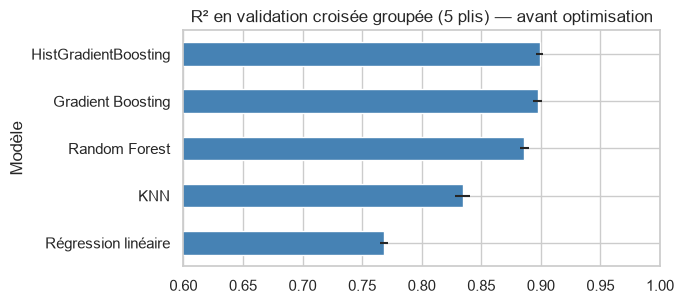

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
base["R² CV"].sort_values().plot.barh(ax=ax, xerr=base["± R²"].reindex(base["R² CV"].sort_values().index), color="steelblue")
ax.set_xlim(0.6, 1); ax.set_title("R² en validation croisée groupée (5 plis) — avant optimisation"); plt.tight_layout(); plt.show()

**Lecture.** La régression linéaire plafonne : la relation entre les caractéristiques et le prix n'est pas linéaire (effet du quartier, de la qualité de construction, interactions surface × localisation). Le KNN profite de la localisation mais traite toutes les variables comme également importantes. Les méthodes à base d'arbres, surtout le boosting, captent bien ces effets. On optimise donc les modèles non linéaires à l'étape suivante.

## 4. Grid search (étape 10)

`GridSearchCV` teste toutes les combinaisons d'une grille d'hyperparamètres par validation croisée groupée (3 plis, pour limiter le temps de calcul) et ré-entraîne le meilleur sur tout le train. Le critère est le RMSE sur log(prix). Les grilles sont volontairement modestes (le calcul tourne sur un seul cœur) mais couvrent les paramètres qui contrôlent le plus le sur-apprentissage.

| Modèle | Hyperparamètres explorés |
|---|---|
| KNN | nombre de voisins, pondération, distance (L1/L2) |
| Random Forest | `max_features`, `min_samples_leaf` |
| Gradient Boosting | `max_depth`, `learning_rate` |
| HistGradientBoosting | `learning_rate`, `max_iter`, `max_leaf_nodes`, `l2_regularization` |

In [14]:
grids = {
    "KNN": (make_pipeline(StandardScaler(), KNeighborsRegressor()),
            {"kneighborsregressor__n_neighbors": [5, 10, 15, 20],
             "kneighborsregressor__weights": ["uniform", "distance"],
             "kneighborsregressor__p": [1, 2]}),
    "Random Forest": (RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=RS),
            {"max_features": [0.5, 1.0], "min_samples_leaf": [1, 3]}),
    "Gradient Boosting": (GradientBoostingRegressor(n_estimators=300, random_state=RS),
            {"max_depth": [3, 4, 5], "learning_rate": [0.05, 0.1]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=RS),
            {"learning_rate": [0.05, 0.1], "max_iter": [300, 600],
             "max_leaf_nodes": [31, 63], "l2_regularization": [0.0, 1.0]}),
}

cv3 = GroupKFold(n_splits=3)
searches, rows = {}, []
for name, (est, grid) in grids.items():
    t = time.time()
    gs = GridSearchCV(est, grid, cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True)
    gs.fit(X_tr, y_tr, groups=g_tr)
    searches[name] = gs
    rows.append({"Modèle": name, "Combinaisons": len(gs.cv_results_["params"]),
                 "Meilleur RMSE CV (log)": -gs.best_score_, "Temps (s)": round(time.time() - t),
                 "Meilleurs paramètres": {k.split("__")[-1]: v for k, v in gs.best_params_.items()}})
    print(f"{name:22s} RMSE log = {-gs.best_score_:.4f}  ({rows[-1]['Temps (s)']} s)")
tuned = pd.DataFrame(rows).set_index("Modèle").sort_values("Meilleur RMSE CV (log)")
tuned

KNN                    RMSE log = 0.2096  (13 s)
Random Forest          RMSE log = 0.1769  (24 s)
Gradient Boosting      RMSE log = 0.1684  (151 s)
HistGradientBoosting   RMSE log = 0.1670  (63 s)


,Combinaisons,Meilleur RMSE CV (log),Temps (s),Meilleurs paramètres
Modèle,,,,
HistGradientBoosting,16,0.167004,63,"{'l2_regularization': 0.0, 'learning_rate': 0...."
Gradient Boosting,6,0.168413,151,"{'learning_rate': 0.1, 'max_depth': 5}"
Random Forest,4,0.176861,24,"{'max_features': 0.5, 'min_samples_leaf': 1}"
KNN,16,0.209621,13,"{'n_neighbors': 10, 'p': 1, 'weights': 'distan..."


### Un grid search a-t-il vraiment aidé ?
On compare, sur les mêmes 3 plis, le RMSE avant (réglages par défaut) et après optimisation.

In [ ]:
avant = {}
for name, (est, _) in grids.items():
    default = {"KNN": models["KNN"], "Random Forest": models["Random Forest"],
               "Gradient Boosting": models["Gradient Boosting"], "HistGradientBoosting": models["HistGradientBoosting"]}[name]
    s = cross_validate(default, X_tr, y_tr, groups=g_tr, cv=cv3, scoring="neg_root_mean_squared_error")
    avant[name] = -s["test_score"].mean()
cmp = pd.DataFrame({"RMSE avant (log)": pd.Series(avant),
                    "RMSE après grid search (log)": tuned["Meilleur RMSE CV (log)"]})
cmp["Gain (%)"] = (1 - cmp.iloc[:, 1] / cmp.iloc[:, 0]) * 100
cmp.round(4).sort_values("RMSE après grid search (log)")

## 5. Évaluation finale sur le jeu de test

On retient le modèle au **meilleur RMSE en validation croisée**, puis on le mesure une seule fois sur le test, à côté de la baseline linéaire et des modèles par défaut pour situer le gain total.

In [ ]:
best_name = tuned.index[0]
best_model = searches[best_name].best_estimator_
print("Modèle retenu :", best_name, "|", tuned.loc[best_name, "Meilleurs paramètres"])

def evaluer(model, label):
    p_log = model.predict(X_te)
    p, t = np.exp(p_log), np.exp(y_te)
    return {"Modèle": label, "R² (log)": r2_score(y_te, p_log), "R² ($)": r2_score(t, p),
            "RMSE ($)": root_mean_squared_error(t, p), "MAE ($)": mean_absolute_error(t, p),
            "MAPE (%)": np.mean(np.abs(p - t) / t) * 100, "Erreur médiane (%)": np.median(np.abs(p - t) / t) * 100}

res = []
for name, m in models.items():
    res.append(evaluer(m.fit(X_tr, y_tr), f"{name} (défaut)"))
for name, gs in searches.items():
    res.append(evaluer(gs.best_estimator_, f"{name} (optimisé)"))
final = pd.DataFrame(res).set_index("Modèle").sort_values("R² (log)", ascending=False)
final.round(3)

### Prédictions vs réalité et distribution des erreurs

In [ ]:
p_te = np.exp(best_model.predict(X_te)); t_te = np.exp(y_te.values)
ape = (p_te - t_te) / t_te * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(t_te / 1e6, p_te / 1e6, s=6, alpha=.35)
lim = max(t_te.max(), p_te.max()) / 1e6; ax[0].plot([0, lim], [0, lim], "r--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set(xlabel="Prix réel (M$, échelle log)", ylabel="Prix prédit (M$, échelle log)", title=f"{best_name} — test")
ax[1].hist(ape.clip(-60, 60), bins=60, color="steelblue"); ax[1].axvline(0, color="r", ls="--")
ax[1].set(xlabel="Erreur relative (%)", title="Distribution des erreurs (tronquée à ±60 %)")
plt.tight_layout(); plt.show()

print(f"{(np.abs(ape) <= 10).mean():.0%} des estimations sont à ±10 % du prix réel, "
      f"{(np.abs(ape) <= 20).mean():.0%} à ±20 %.")

In [ ]:
# Où le modèle se trompe-t-il le plus ? (par tranche de prix réel)
tranches = pd.qcut(t_te, 5, labels=["Q1 (moins cher)", "Q2", "Q3", "Q4", "Q5 (plus cher)"])
pd.DataFrame({"tranche": tranches, "erreur abs. (%)": np.abs(ape), "biais (%)": ape}).groupby("tranche", observed=True).agg(
    MAPE=("erreur abs. (%)", "mean"), biais=("biais (%)", "mean")).round(1)

**Lecture.** Le modèle a tendance à **surestimer** les biens les moins chers et à **sous-estimer** les plus chers (régression vers la moyenne, classique) ; les biens de luxe sont aussi les plus rares, donc les plus difficiles. L'outil est fiable pour des biens « standard », et ses estimations sur des biens atypiques doivent être prises comme un ordre de grandeur.

### Importance des variables (permutation)

In [ ]:
imp = permutation_importance(best_model, X_te, y_te, n_repeats=5, random_state=RS, scoring="r2")
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), color="steelblue", title="Perte de R² quand on mélange la variable (test)"); plt.tight_layout(); plt.show()

La **latitude** domine très largement (le gradient nord-sud est marqué dans le comté : Seattle, Bellevue et le nord contre le sud), suivie de la **surface habitable** (`sqft_living`), de la **qualité de construction** (`grade`) et de la **longitude**. Les autres variables pèsent peu une fois ces quatre-là connues : on retrouve ce que les agents immobiliers répètent (« l'emplacement, l'emplacement, l'emplacement »), et c'est cohérent avec les résultats de la sélection de variables de l'étape 8.

## 6. Sauvegarde pour l'application Flask

On sauvegarde le modèle, ainsi que des métadonnées utiles à l'application :
- la liste ordonnée des variables ;
- les **quantiles 10 % / 90 % des erreurs en log** sur le test, pour afficher une **fourchette** autour de l'estimation ;
- les coordonnées médianes par code postal (l'utilisateur choisit un code postal, l'app en déduit lat/long et les caractéristiques du voisinage) ;
- les bornes observées dans les données d'entraînement, pour avertir quand on sort de la zone de confiance du modèle.

**Réentraînement final :** le modèle retenu est ré-entraîné sur **toutes** les données (train + test) avant export, avec les hyperparamètres choisis ; les métriques affichées plus haut restent celles mesurées sur le test.

In [ ]:
resid = y_te.values - best_model.predict(X_te)
q10, q90 = np.quantile(resid, [0.10, 0.90])

from sklearn.base import clone
deployed = clone(best_model).fit(X, y)

zips = (df.groupby("zipcode").agg(lat=("lat", "median"), long=("long", "median"),
        sqft_living15=("sqft_living15", "median"), sqft_lot15=("sqft_lot15", "median"), n=("price", "size"))
        .round(4).to_dict(orient="index"))

meta = {
    "model_name": best_name,
    "best_params": {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                    for k, v in tuned.loc[best_name, "Meilleurs paramètres"].items()},
    "features": FEATURES,
    "ref_year": 2015,                      # année de référence pour house_age (données de 2014-2015)
    "log_resid_q10": float(q10), "log_resid_q90": float(q90),
    "test_metrics": {k: round(float(v), 4) for k, v in final.loc[f"{best_name} (optimisé)"].items()},
    "bounds": {c: [float(X[c].min()), float(X[c].max())] for c in FEATURES},
    "zipcodes": zips,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(deployed, MODEL_DIR / "model.joblib", compress=3)
(MODEL_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print("Modèle et métadonnées sauvegardés dans", MODEL_DIR.resolve())
print(f"Fourchette d'erreur à 80 % : de {np.exp(q10) - 1:+.0%} à {np.exp(q90) - 1:+.0%} autour de l'estimation")

## 7. Conclusion

**Réponse à la problématique.** Oui : un modèle de boosting d'arbres, entraîné sur 16 variables sélectionnées, estime le prix d'un bien avec une erreur médiane d'environ 8 % (58 % des estimations à ±10 %, 83 % à ±20 %) et explique environ 90 % de la variance de log(prix) sur des biens jamais vus. Une simple régression linéaire n'en explique que 77 % et se trompe de près de 16 % en médiane.

**Points clés de la démarche**
- Découpage groupé par `id` et cible en log : deux garde-fous contre une évaluation trop optimiste ou dominée par les prix extrêmes.
- La comparaison par validation croisée a montré que la non-linéarité compte plus que le réglage fin : l'écart modèle linéaire → modèle à arbres est bien supérieur au gain du grid search.
- Le grid search apporte un gain modeste (environ 1 % de RMSE pour les arbres, 4 % pour le KNN) ; les grilles restent limitées par le temps de calcul.

**Limites**
- Données de **mai 2014 à mai 2015** et d'un seul comté : les prix actuels et les autres marchés ne sont pas couverts (l'app le précise).
- Précision moindre sur les biens très chers ou atypiques.
- Pas de variables sur l'état intérieur, la rue, les écoles, etc., qui expliquent une partie de l'erreur restante.

**Choix du modèle déployé :** `HistGradientBoosting` optimisé a le meilleur RMSE en validation croisée ; il est quasi à égalité avec le `GradientBoosting` optimisé sur le test (R² log 0,904 pour les deux) mais environ 5× plus rapide à entraîner, ce qui compte pour réentraîner régulièrement avec de nouvelles données.

**Pistes d'amélioration :** grilles plus larges ou recherche aléatoire/bayésienne, XGBoost/LightGBM, variables géographiques supplémentaires (distance au centre de Seattle, au front de mer), mise à jour avec des données récentes.